# Projet Leyenda: from a scanned image to a captioned photo

**Client:** TouNum, digitization of paper archives

**Team:** Fernanda Gentil, Haytam El hilali, Felipe Lobos (CESI, Data Science)





## 0. The need

TouNum scans paper archives and wants to **caption the photos automatically**, so they can be searched. Two problems:

- the archives don't only contain photos: there are also **text pages, drawings, paintings and diagrams**, and these must not be captioned;
- many photos are **noisy** (grain, scanning, compression).

So we built the pipeline in three steps, one per deliverable:

```
 scanned image ──► 1. Is it a photo? ──► 2. Is it noisy? Denoise ──► 3. Write a caption
                     CNN classifier         U-Net denoiser             InceptionV3 + attention + GRU
                     │ no
                     └──► set aside
```

> **To say:** each step was built and evaluated on its own, then the three models are put together in Part 4.

In [13]:
# Setup: libraries, paths and the three final models
import base64, json, math, os, sys
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"     # hide the TensorFlow info messages

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageOps
from IPython.display import display, Image as IPImage

def local_path(windows_path):
    # Works on Windows and under WSL (C:\... becomes /mnt/c/...)
    if os.name == "nt":
        return Path(windows_path)
    return Path("/mnt/" + windows_path[0].lower() + windows_path[2:].replace("\\", "/"))

ROOT = local_path(r"C:\Projet data")                               # the project folder
PICTURES_DIR = local_path(r"C:\Users\Ihssa\Downloads\pictures")   # 17 web images, never seen in training

# Same pipeline as the demo app: L1 classifier, L2 U-Net, L3 captioning model
sys.path.insert(0, str(ROOT / "backend"))
import pipeline as P
pipe = P.Pipeline()

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".jpe", ".png", ".webp", ".bmp"}
paths = sorted(p for p in PICTURES_DIR.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)

# The real class of each test image (we checked them by eye): the 7 photos, the rest is not a photo
TRUE_PHOTOS = {"2.jpg", "dog.JPEG", "hotdog.JPEG", "images (3).jpe", "images (4).jpe",
               "photo_0000.jpg", "photo_0001.jpg"}

def open_rgb(path):
    # Opens an image the right way up (EXIF) and in RGB
    return ImageOps.exif_transpose(Image.open(path)).convert("RGB")

def show_figure(notebook, starts_with, which=None, width=900):
    # Shows a figure saved in one of our notebooks: the image outputs of the code cell that starts with `starts_with`
    nb = json.loads((ROOT / notebook).read_text(encoding="utf-8"))
    for cell in nb["cells"]:
        if cell["cell_type"] == "code" and "".join(cell["source"]).startswith(starts_with):
            pngs = [o["data"]["image/png"] for o in cell.get("outputs", []) if "image/png" in o.get("data", {})]
            for k, png in enumerate(pngs):
                if which is None or k in which:
                    png = png if isinstance(png, str) else "".join(png)
                    display(IPImage(data=base64.b64decode(png), width=width))
            return
    print("Figure not found in", notebook)

print(f"Models loaded | {len(paths)} test images in {PICTURES_DIR}")

Models loaded | 17 test images in C:\Users\Ihssa\Downloads\pictures


c:\Users\Ihssa\anaconda3\Lib\site-packages\keras\src\layers\layer.py:413: UserWarning: `build()` was called on layer 'rnn__decoder_v2_2', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


## 1. Livrable 1: is it a photo? (5 min)

**Data.** About 41,700 scanned images in five folders: photos, paintings, diagrams, drawings and text. We turned it into a **binary** problem: *photo* against *not a photo*. Only 24 % of the images are photos. 80 % of the images are used for training and 20 % for the test (8,339 images).

**Model.** A CNN on 180×180 images: three blocks `Conv2D` + `MaxPooling2D` (16, 32, 64 filters) that learn edges, then textures, then shapes, a dense layer of 128 neurons, and 2 outputs (photo / not a photo).

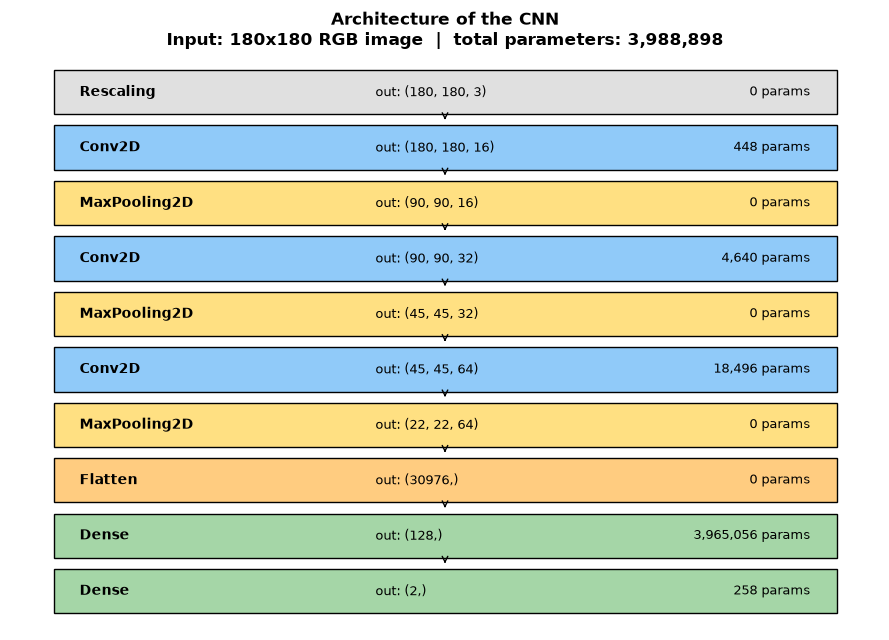

In [14]:
# Architecture of our CNN: output size and number of parameters of each layer
show_figure("Livrable1_Classification_Photo.ipynb", "def draw_architecture(model, title):", width=800)

**What we see.** About **4 million parameters**, and 99 % of them (3.97 million) are in the first dense layer: the 30,976 values that come out of `Flatten` are all connected to its 128 neurons. That's where the network has room to learn the training images by heart.

**The problem we hit: overfitting.** Our first model reached 99.1 % on its training images but 91.1 % on the test images, and its test loss went back up after epoch 2 (0.216 then 0.431). It was learning the training images by heart.

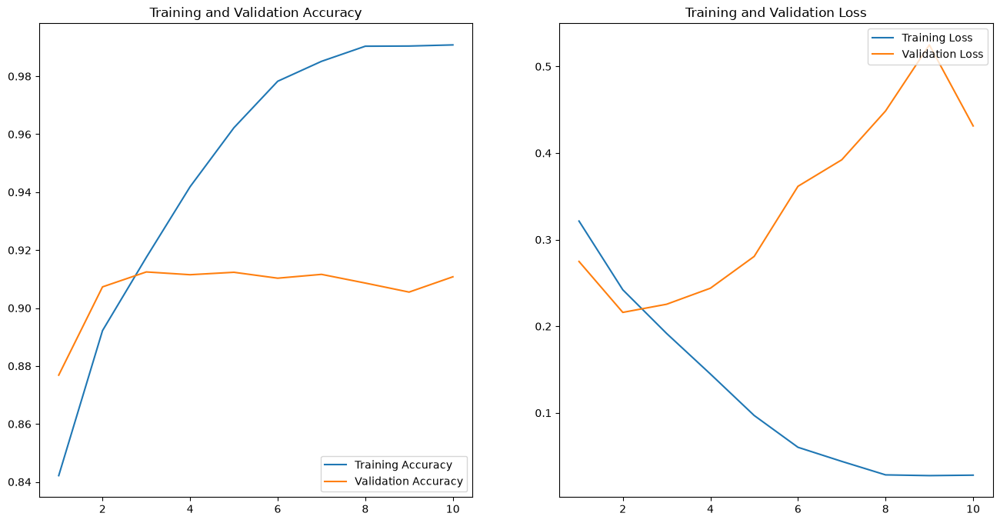

In [15]:
# First model: training accuracy keeps going up, test loss goes back up after epoch 2
show_figure("Livrable1_Classification_Photo.ipynb", "acc = history.history['accuracy']")

**What we changed.** Three methods against overfitting:

- **dropout** (20 %, before `Flatten`): random values switched off during training, so the network can't rely on a few of them;
- **data augmentation**: random horizontal flips, rotations (up to 18°) and zooms (up to 10 %), so every epoch sees slightly different images;
- **early stopping**: we keep the weights of the best epoch (here epoch 8 out of 11).

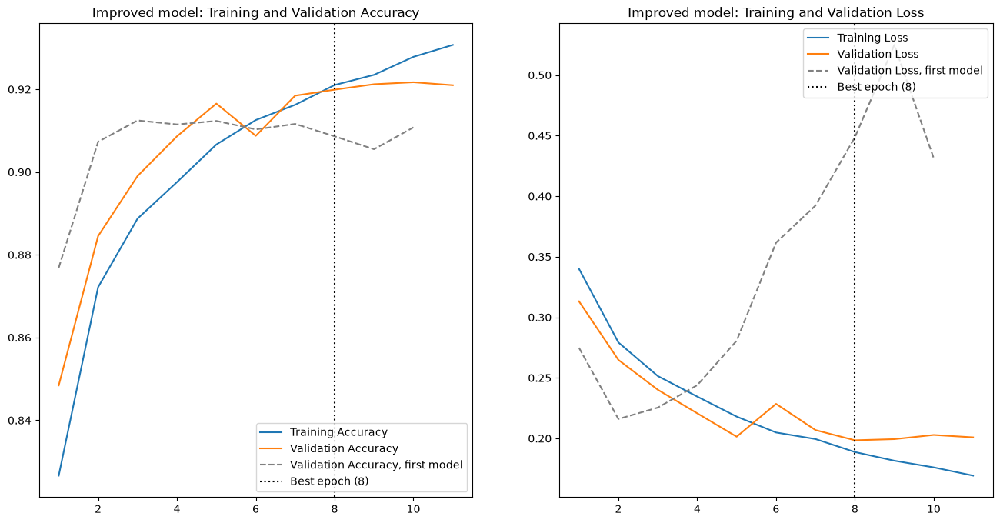

In [16]:
# Improved model: training and test curves now stay together
show_figure("Livrable1_Classification_Photo.ipynb", "imp_acc = improved_history.history['accuracy']")

| | Train accuracy | Test accuracy | Gap | Test loss |
|---|---|---|---|---|
| First model, last epoch | 99.1 % | 91.1 % | 8.0 points | 0.431 |
| **Improved model** | 92.1 % | **92.0 %** | **0.1 point** | **0.198** |

The improved model is a bit better on the test set, and above all it **generalises**: almost no gap between training and test.

**Live test** on 17 images from the web, never seen during training (paintings, drawings, a diagram, a screenshot and 7 photos). Green means the model is right.

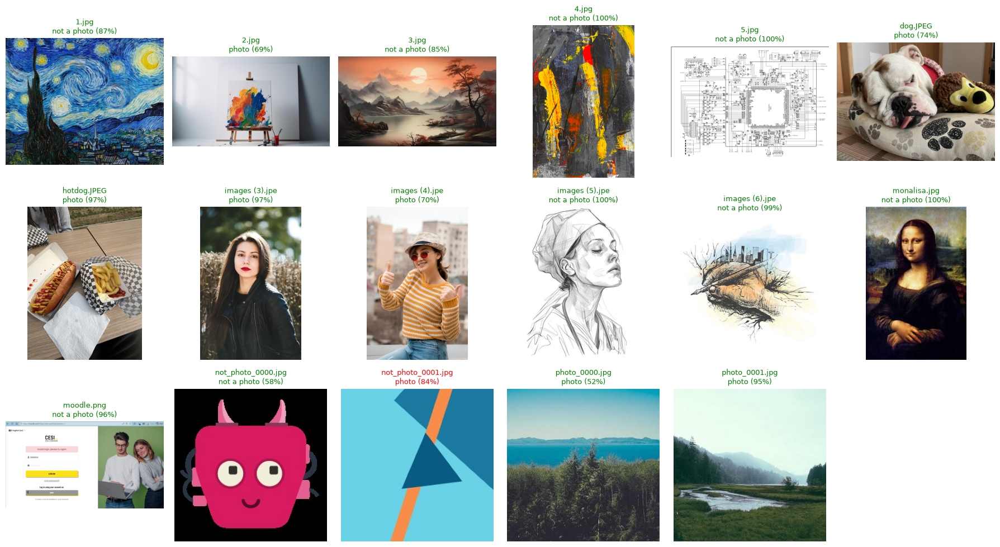

16 / 17 images correctly classified


In [17]:
# Live demo: the improved classifier on the 17 web images
cols = 6
rows = math.ceil(len(paths) / cols)
plt.figure(figsize=(3 * cols, 3.3 * rows))
correct = 0
for k, path in enumerate(paths):
    image = open_rgb(path)
    p_photo = pipe.photo_probability(image)
    is_photo = p_photo > P.PHOTO_THRESHOLD
    right = is_photo == (path.name in TRUE_PHOTOS)
    correct += right
    plt.subplot(rows, cols, k + 1)
    plt.imshow(image)
    label = f"photo ({p_photo:.0%})" if is_photo else f"not a photo ({1 - p_photo:.0%})"
    plt.title(f"{path.name}\n{label}", fontsize=9, color="green" if right else "red")
    plt.axis("off")
plt.tight_layout()
plt.show()
print(f"{correct} / {len(paths)} images correctly classified")

**What we see.** 16 images out of 17 are right: the Van Gogh, the Mona Lisa, the drawings, the circuit diagram and the screenshot are all set aside. The only mistake is `not_photo_0001`, a flat abstract graphic with smooth colours, taken for a photo.

> **To say:** the mistakes are on images that look "realistic" (smooth gradients, like a photo). That's where more data or transfer learning would help.

## 2. Livrable 2: removing the noise (5 min)

**Data.** 148 RGB photos of all sizes, split into 103 training, 22 validation and 23 test photos.

**The idea.** To learn to denoise, a network needs pairs (noisy photo, clean photo). So we **add Gaussian noise ourselves** to the photos (a new random noise at every epoch, σ between 0.05 and 0.2) and train the network to give back the original. We evaluate at σ = 0.10.

**What we tried.** Seven methods, all on the **same 23 test photos** with the **same noise** (σ = 0.10):

| Rank | Method | The idea | PSNR | SSIM | Sharpness kept |
|---|---|---|---|---|---|
| **1 (best)** | **U-Net v3** | auto-encoder + **skip connections** | **29.91 dB** | **0.847** | **65.2 %** |
| 2 | Auto-encoder v2 | same model, trained on ~5,000 patches of 64×64 at the **real resolution** | 28.07 dB | 0.801 | 35.9 % |
| 3 | Gaussian blur (σ = 1) | classic filter | 25.33 dB | 0.669 | 4.2 % |
| 4 | Auto-encoder v1 | trained on whole photos shrunk to 128×128 | 24.34 dB | 0.667 | 3.3 % |
| 5 | Median filter 3×3 | classic filter | 24.31 dB | 0.565 | 22.1 % |
| 6 | Residual learning* | the network predicts the noise, which is then subtracted from the photo | 21.57 dB | 0.508 | (noise still there) |
| 7 (worst) | Noisy photo | no processing | 20.41 dB | 0.409 | (noise) |

\*Measured on the photos shrunk to 128×128, in Fernanda's run.

*PSNR: how close the result is to the original photo (higher is better). SSIM: how well the structure is kept (1 = identical). Sharpness kept: how much of the fine detail of the original is still there.*

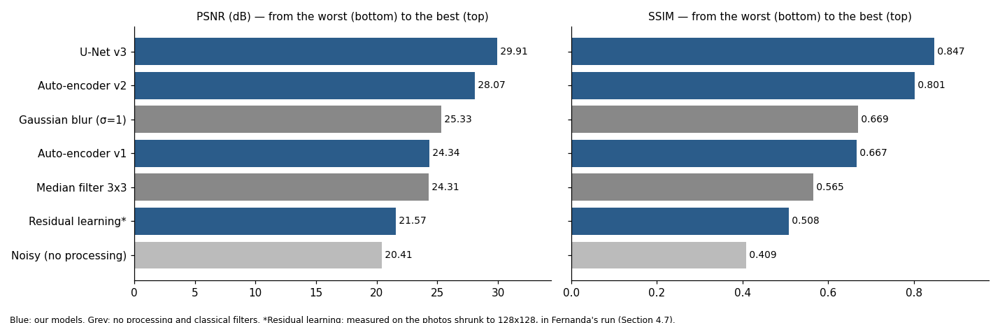

**Why we kept the U-Net.**

- **It's the best on every metric**: +9.5 dB over the noisy photo, +1.8 dB over v2, and it beats v2 on **all 23** test photos.
- **It keeps the details.** The blur and our first auto-encoder remove the noise by smoothing everything: they keep only 4 % and 3 % of the fine detail. The U-Net keeps 65 %, almost twice as much as v2.
- **We understood why.** In an auto-encoder, everything goes through the bottleneck (the photo is reduced to 32×32), so the fine details are lost. The skip connections of the U-Net let them go around it. Residual learning confirmed that the bottleneck was the problem: changing only what the network predicts did not help at all.
- **On the real photos it changes them the least**: 36.2 dB from the originals, against 29.5 dB for v2.
- **It works on photos of any size**, because it only contains convolutions.

> **To say:** our first model lost to a simple blur. More data (patches at the real resolution) gave the biggest jump, +3.7 dB, and the better architecture (U-Net) the next one, +1.8 dB.

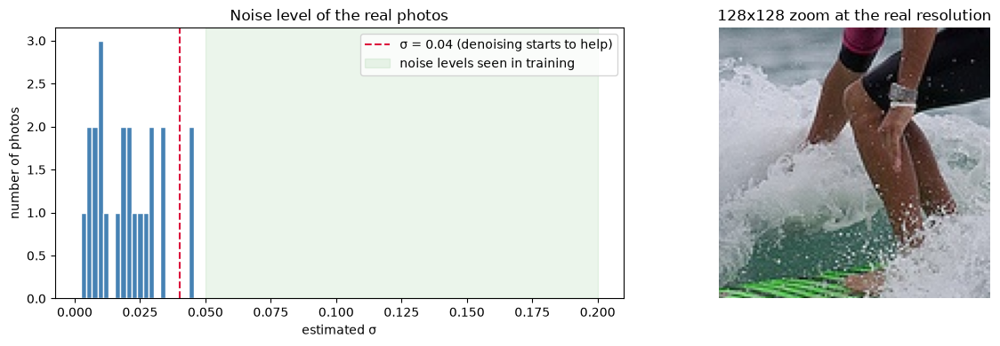

In [18]:
# The real photos are barely noisy: estimated noise level of the dataset photos
show_figure("Livrable2_Denoising_final.ipynb", "def estimate_noise_sigma(channel):")

**A finding that changed the pipeline.** We estimated the real noise of the photos (Immerkaer estimator): about **σ = 0.02**, and only 2 test photos out of 23 are above 0.04. On a photo that is already this clean, denoising does more harm than good. So in the pipeline we **measure the noise first** and only denoise above σ = 0.04.

**Live test** on a web photo never seen in training: we add noise σ = 0.10, then denoise it with the U-Net.

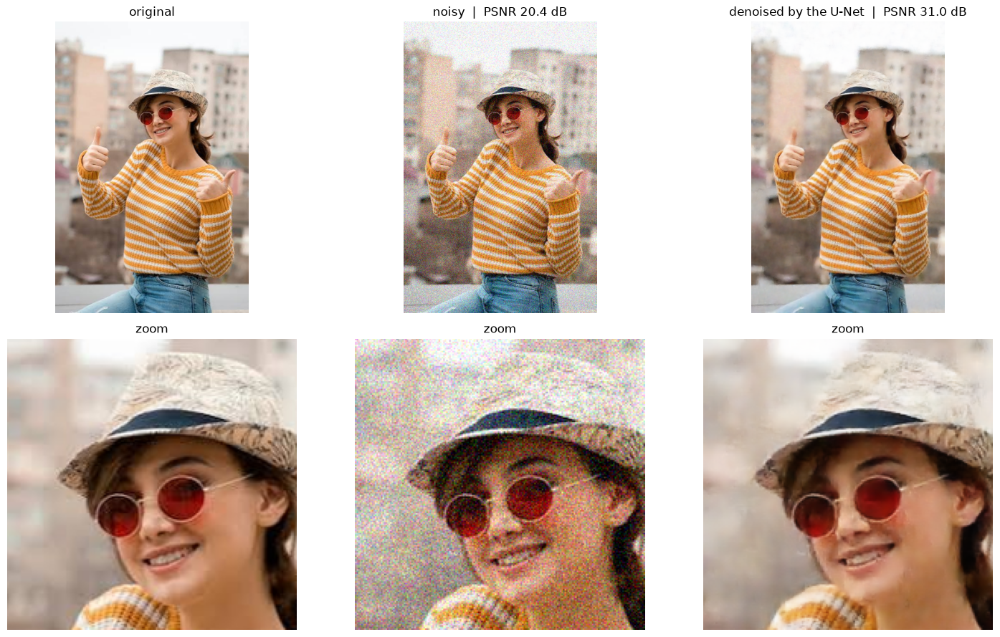

original photo  estimated σ = 0.008 -> keep as it is
noisy photo     estimated σ = 0.096 -> denoise
Denoising the clean photo anyway changes it: PSNR 37.4 dB from the original


In [19]:
# Live demo: noise added on purpose, then removed by the U-Net (v3)
SIGMA = 0.10
photo = open_rgb(PICTURES_DIR / "images (4).jpe")
photo.thumbnail((P.MAX_SIDE, P.MAX_SIDE))                 # same size as in the pipeline
clean = np.asarray(photo, dtype=np.float32) / 255.0
noisy = np.clip(clean + np.random.default_rng(0).normal(0, SIGMA, clean.shape), 0, 1).astype(np.float32)
denoised = pipe.denoise(noisy)

psnr = lambda a, b: float(tf.image.psnr(a, b, max_val=1.0))
noise_level = lambda x: float(np.mean([P.estimate_noise_sigma(x[..., c]) for c in range(3)]))

h, w = clean.shape[:2]
zoom = (slice(int(0.15 * h), int(0.45 * h)), slice(int(0.30 * w), int(0.75 * w)))   # zoom on the face and the hat
panels = [(clean, "original"), (noisy, f"noisy  |  PSNR {psnr(noisy, clean):.1f} dB"),
          (denoised, f"denoised by the U-Net  |  PSNR {psnr(denoised, clean):.1f} dB")]
plt.figure(figsize=(15, 9))
for k, (img, title) in enumerate(panels):
    plt.subplot(2, 3, k + 1); plt.imshow(img); plt.title(title); plt.axis("off")
    plt.subplot(2, 3, k + 4); plt.imshow(img[zoom]); plt.title("zoom"); plt.axis("off")
plt.tight_layout()
plt.show()

# The noise gate: what the pipeline would decide for each version of the photo
for name, img in [("original photo", clean), ("noisy photo", noisy)]:
    s = noise_level(img)
    print(f"{name:15s} estimated σ = {s:.3f} -> {'denoise' if s > P.NOISE_THRESHOLD else 'keep as it is'}")
print(f"Denoising the clean photo anyway changes it: PSNR {psnr(pipe.denoise(clean), clean):.1f} dB from the original")

**What we see.** The PSNR goes from about 20 dB (noisy) to about 31 dB (denoised): the grain disappears, but on the zoom the finest textures are a little softer, which is the *loss of detail* asked for in the case study. The noise gate measures about σ = 0.01 on the original and σ = 0.10 on the noisy version, so only the noisy one goes to the U-Net. Even on the clean photo the U-Net is not neutral (about 37 dB from the original): that's why we don't denoise clean photos.

> **To say:** our denoiser was trained on Gaussian noise that we added, which is not exactly the noise of a real scan. That's its main limit.

## 3. Livrable 3: writing a caption (5 min)

**Architecture** (encoder-decoder with attention):

```
 photo ──► InceptionV3 (pre-trained on ImageNet) ──► 8×8 grid of features ──► CNN encoder (dense 256)
                                                     (computed once, stored on disk)        │
                                                                                             ▼
 "a man riding a wave"  ◄── GRU decoder (512) ◄── attention: which part of the photo, for each word?
```

**Data.** MS COCO 2014: 82,783 photos with about 5 captions each, split into **74,145 training, 8,238 validation and 400 test photos**. Captions are cleaned, cut into words, and the vocabulary keeps the words seen at least 5 times (8,467 words).

**From the first model to the final one:**

| | First model | Final model |
|---|---|---|
| Training photos | 1,600 | **74,145** (all of COCO) |
| Word vectors | random | **GloVe** (pre-trained, still trainable) |
| Against overfitting | nothing | **dropout** + validation + **early stopping** |
| Writing the caption | random draw of each word | **beam search** (3 best sentences kept) |
| Test loss per word | 4.933 | **2.800** |

The training on all of COCO took about 5 h 30 on our laptop GPU (25 epochs, best epoch 22). To make it possible, we packed the features into big float16 files, so the USB drive is read in one go.

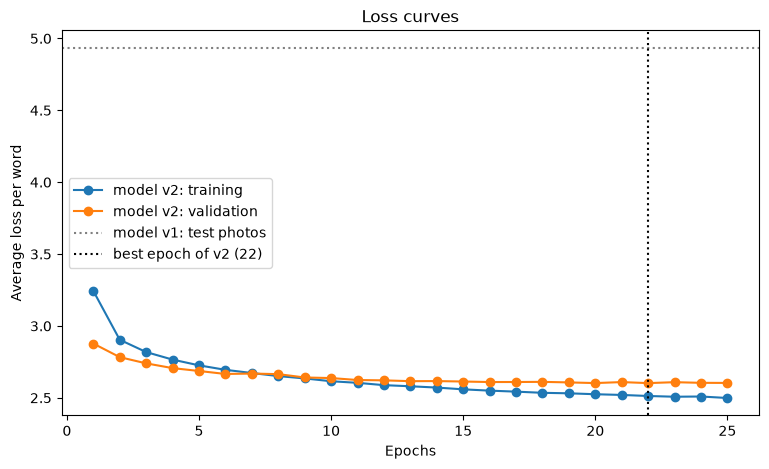

In [20]:
# Loss curves of the final model, with the first model for comparison
show_figure("Livrable3_Captioning.ipynb", "test_loss_v2 = mean_word_loss(loss_step2, test_ds2)")



**Live test** on our web photos, and where the model looks for each word. The pipeline uses a slightly better beam search than the notebook (5 sentences kept, no repeated words), so a few captions can differ from Livrable 3.

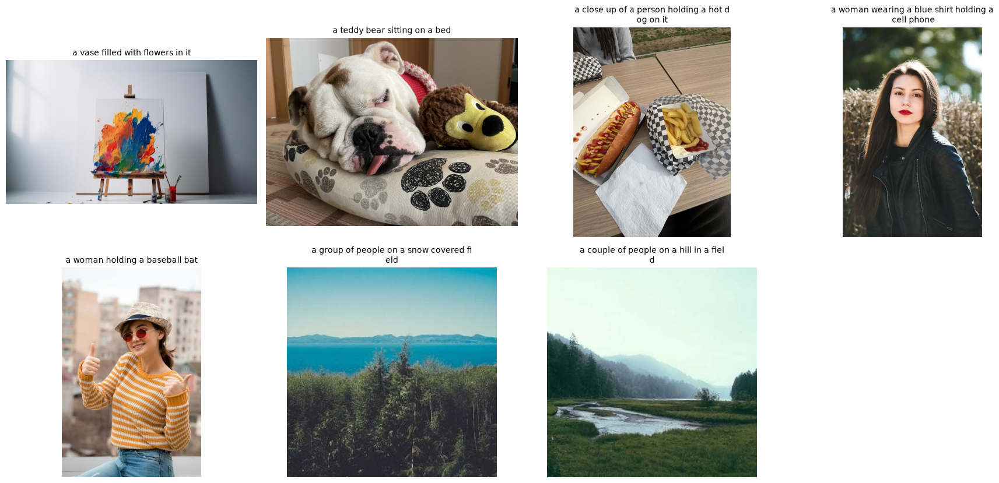

In [22]:
# Live demo: captions of the 7 web photos (beam search of the pipeline)
web_photos = [p for p in paths if p.name in TRUE_PHOTOS]
cols = 4
rows = math.ceil(len(web_photos) / cols)
plt.figure(figsize=(4.5 * cols, 4.2 * rows))
for k, path in enumerate(web_photos):
    image = open_rgb(path)
    caption = pipe.beam_search(pipe.encode_image(image))[0]
    plt.subplot(rows, cols, k + 1)
    plt.imshow(image)
    plt.title("\n".join([caption[i:i + 38] for i in range(0, len(caption), 38)]), fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

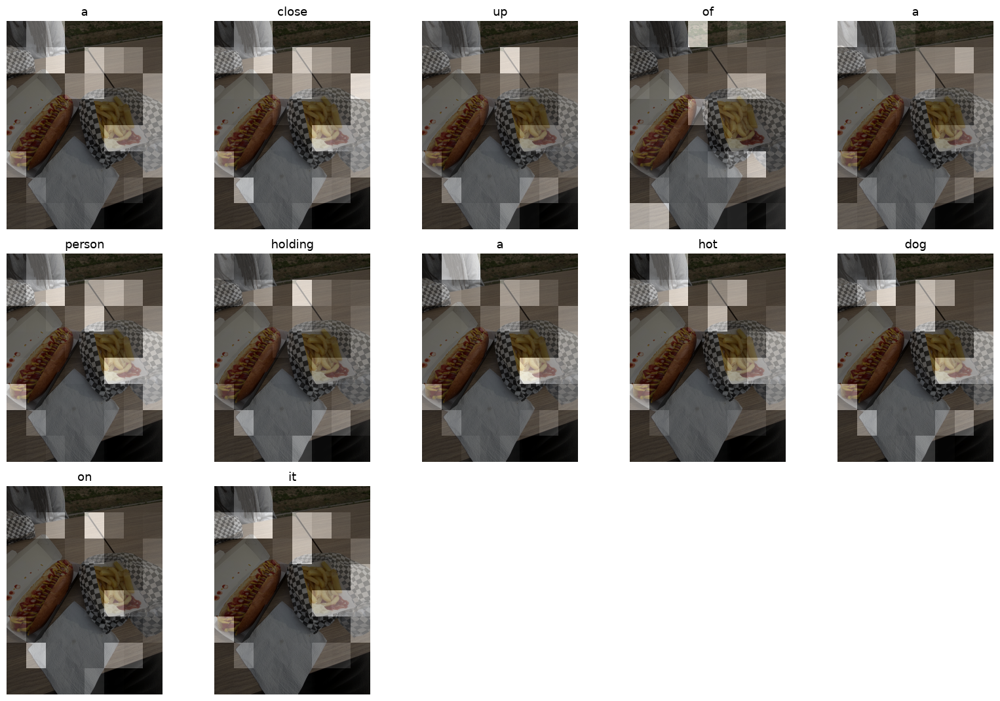

In [23]:
# Live demo: where the model looks when it writes each word (attention map, 8x8 regions)
def caption_with_attention(image):
    features = pipe.encode_image(image)
    words = pipe.beam_search(features)[0].split()
    hidden = pipe.decoder.reset_state(batch_size=1)
    dec_input = tf.constant([[pipe.start_id]])
    maps = []
    for word in words:
        # the caption is fed back word by word, and we keep the attention of each step
        _, hidden, attention = pipe.decoder(dec_input, features, hidden)
        maps.append(tf.reshape(attention, (8, 8)).numpy())
        dec_input = tf.constant([[pipe.tokenizer.word_index.get(word, pipe.unk_id)]])
    return words, maps

image = open_rgb(PICTURES_DIR / "hotdog.JPEG")
words, maps = caption_with_attention(image)
cols = 5
rows = math.ceil(len(words) / cols)
plt.figure(figsize=(3.2 * cols, 3.6 * rows))
for k, (word, attention_map) in enumerate(zip(words, maps)):
    ax = plt.subplot(rows, cols, k + 1)
    shown = ax.imshow(image)
    ax.imshow(attention_map, cmap="gray", alpha=0.6, extent=shown.get_extent())
    ax.set_title(word, fontsize=13)
    ax.axis("off")
plt.tight_layout()
plt.show()

**What we see.** Some captions are right ("a close up of a person holding a hot dog"), but the model often **invents details**: a baseball bat in the hand of the woman with the hat, people in the empty meadow, a snow field instead of the forest by the sea, and the dog is still "a teddy bear sitting on a bed". COCO is full of people doing sports and of animals and toys on beds, and the model picked up these habits. It also only sees each photo as an 8×8 grid, which loses the small details.

> **To say:** on the attention maps, the bright areas show where the model looks when it writes each word.

## 4. The full pipeline, live (2 min)

The three models one after the other on the 17 web images: the non-photos are set aside, the photo is denoised only if its noise level is above 0.04, then it is captioned.

*Expected result:* 8 images go through as photos (the 7 real photos, plus the abstract graphic that Livrable 1 gets wrong), none of them is noisy enough to be denoised, and 9 images are set aside.

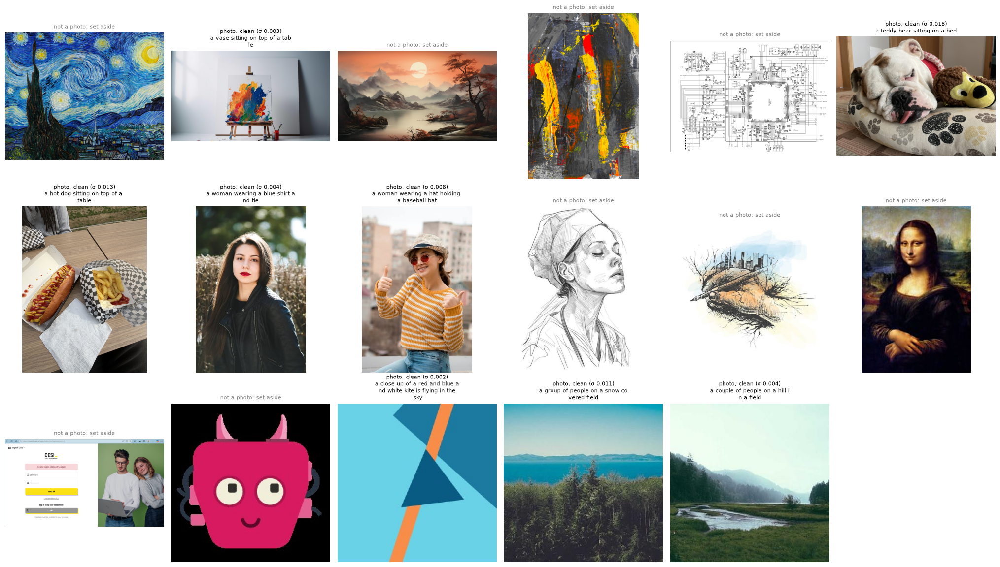

17 images: 8 photos captioned (0 denoised), 9 set aside


In [24]:
# Live demo: the whole pipeline on the folder (same code as the demo app)
results = [(path, pipe.process(open_rgb(path))) for path in paths]

cols = 6
rows = math.ceil(len(results) / cols)
plt.figure(figsize=(3.4 * cols, 3.9 * rows))
for k, (path, r) in enumerate(results):
    plt.subplot(rows, cols, k + 1)
    plt.imshow(open_rgb(path))
    if not r["is_photo"]:
        text, color = "not a photo: set aside", "gray"
    else:
        step2 = "denoised" if r["denoised"] else "clean"
        caption = "\n".join([r["caption"][i:i + 30] for i in range(0, len(r["caption"]), 30)])
        text, color = f"photo, {step2} (σ {r['noise_level']:.3f})\n{caption}", "black"
    plt.title(text, fontsize=8, color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

n_photos = sum(r["is_photo"] for _, r in results)
n_denoised = sum(r["denoised"] for _, r in results)
print(f"{len(results)} images: {n_photos} photos captioned ({n_denoised} denoised), {len(results) - n_photos} set aside")

### The demo website

The same pipeline is available in a small web app: a **FastAPI backend** that runs the three models (on the GPU under WSL, about 1 second per photo), and a **web page** where you upload up to 10 images and get, for each one, the photo / not a photo verdict, the noise level, the denoised photo if it was noisy, and the caption with two alternatives.

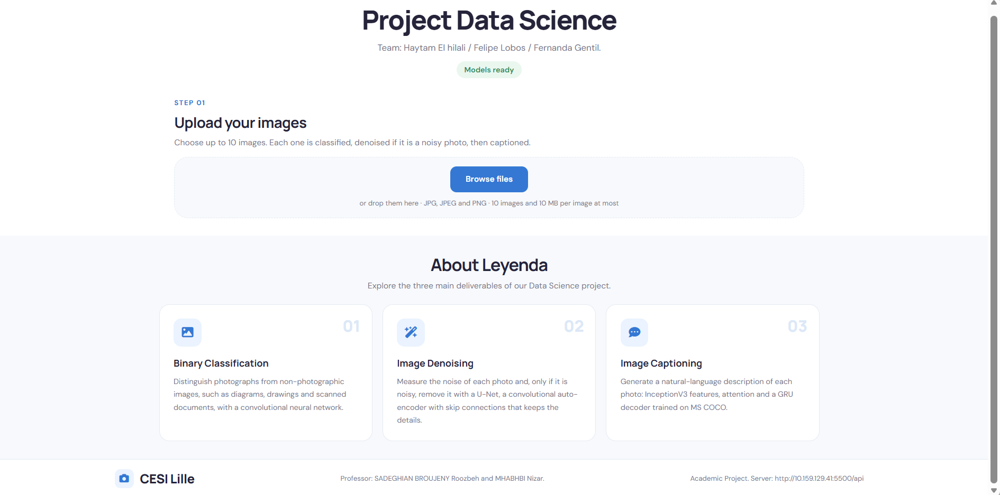

- **"Models ready"** tells that the backend is running and the three models are loaded.
- **Denoising Auto / Always**: by default only the noisy photos go through the U-Net, like in our pipeline.
- **"It's a photo: caption it"**: when the classifier sets a real photo aside (an ID-style portrait for instance), the user can override it, and the page shows what the model had decided.
- The results can be **downloaded as a CSV** file, ready to be given to TouNum.



## 5. Conclusion

| Step | Final model | Result |
|---|---|---|
| 1. Photo or not? | CNN + dropout + data augmentation + early stopping | **92.0 %** test accuracy, no overfitting |
| 2. Denoising | U-Net, only used when the photo is noisy | **29.9 dB** PSNR, SSIM 0.847 |
| 3. Captioning | InceptionV3 + attention + GRU, GloVe, all of COCO, beam search | test loss per word **2.80** (first model 4.93) |

**What we learned**
- Overfitting showed up at every step, and the fixes were the same ideas each time: more data, dropout, validation and early stopping.
- More data mattered more than a bigger model: patches for the denoiser, all of COCO for the captions.
- Measuring before deciding: the noise estimate showed that denoising every photo would have made most of them worse.

**Limits and next steps**
- The captioning model invents details on photos that don't look like COCO. Next: fine-tune the last blocks of InceptionV3 with a low learning rate, and measure the captions with BLEU.
- The denoiser was trained on synthetic Gaussian noise. Next: test it on real noisy scans from TouNum.
- The classifier still confuses some smooth graphics with photos. Next: more examples of this kind, or transfer learning.

**Thank you! Questions?**